<a href="https://colab.research.google.com/github/Mohammedalirubel/GitHub/blob/main/predictive_analytics_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Analytics: Class Demo
### Stock Price Prediction (LSTM) · Sales Forecasting · Waiter Tips Regression · Deployment

This notebook walks through all four parts of the project:
1. Stock price prediction using an LSTM neural network
2. Sales forecasting and time-series analysis
3. Waiter tips prediction and regression refinement
4. Deploying a prediction pipeline

All data here is **synthetic**, generated for teaching purposes.

In [16]:
!pip install -q bdshare

from datetime import date
from functools import lru_cache
from io import StringIO
import re

import pandas as pd
from bdshare import get_historical_data
from fastapi import FastAPI, HTTPException, Query
from fastapi.responses import StreamingResponse

app = FastAPI(title='DSE Historical Data API', version='1.1.0')
COLUMNS = ['DATE', 'TRADING CODE', 'LTP*', 'HIGH', 'LOW', 'OPENP*', 'CLOSEP*', 'YCP', 'TRADE', 'VALUE (mn)', 'VOLUME']
ALIASES = {
    'date': 'DATE', 'tradingcode': 'TRADING CODE', 'symbol': 'TRADING CODE', 'code': 'TRADING CODE',
    'ltp': 'LTP*', 'high': 'HIGH', 'low': 'LOW', 'openp': 'OPENP*', 'open': 'OPENP*',
    'closep': 'CLOSEP*', 'close': 'CLOSEP*', 'ycp': 'YCP', 'trade': 'TRADE',
    'value': 'VALUE (mn)', 'valuemn': 'VALUE (mn)', 'volume': 'VOLUME'
}

def normalize(raw: pd.DataFrame) -> pd.DataFrame:
    if raw is None or raw.empty:
        return pd.DataFrame(columns=COLUMNS)
    df = raw.reset_index().copy()
    df.columns = [ALIASES.get(re.sub(r'[^a-z0-9]', '', str(c).lower()), str(c)) for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    required = {'DATE', 'TRADING CODE', 'CLOSEP*'}
    if not required.issubset(df.columns):
        raise ValueError(f'Unexpected DSE response columns: {list(df.columns)}')
    for col in COLUMNS:
        if col not in df.columns:
            df[col] = None
    df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce').dt.strftime('%Y-%m-%d')
    df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.upper().str.strip()
    for col in COLUMNS[2:]:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False), errors='coerce')
    df = df.dropna(subset=['DATE']).drop_duplicates(subset=['DATE', 'TRADING CODE'])
    return df[COLUMNS].sort_values(['DATE', 'TRADING CODE']).reset_index(drop=True)

@lru_cache(maxsize=32)
def fetch(start: str, end: str, code: str) -> pd.DataFrame:
    # Empty code requests all instruments. The library handles new/legacy DSE sources.
    raw = get_historical_data(start, end, code or None)
    return normalize(raw)

def get_data(start_date: date, end_date: date, trading_code: str | None):
    if start_date > end_date:
        raise HTTPException(400, 'start_date must not be after end_date')
    code = (trading_code or '').strip().upper()
    try:
        df = fetch(start_date.isoformat(), end_date.isoformat(), code).copy()
    except Exception as exc:
        raise HTTPException(502, f'DSE upstream retrieval failed: {exc}') from exc
    if code:
        df = df[df['TRADING CODE'] == code]
    return df

@app.get('/api/dse/data')
def data(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11),
         trading_code: str | None = None, limit: int | None = Query(None, ge=1),
         offset: int = Query(0, ge=0)):
    df = get_data(start_date, end_date, trading_code)
    selected = df.iloc[offset:] if limit is None else df.iloc[offset:offset + limit]
    page = selected.astype(object).where(pd.notna(selected), None)
    return {'total': len(df), 'offset': offset, 'limit': limit, 'returned': len(page), 'columns': COLUMNS,
            'data': page.to_dict(orient='records')}

@app.get('/api/dse/codes')
def codes(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11)):
    df = get_data(start_date, end_date, None)
    return {'count': df['TRADING CODE'].nunique(), 'codes': sorted(df['TRADING CODE'].unique().tolist())}

@app.get('/api/dse/download')
def download(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11),
             trading_code: str | None = None):
    df = get_data(start_date, end_date, trading_code)
    output = StringIO()
    df.to_csv(output, index=False)
    return StreamingResponse(iter([output.getvalue()]), media_type='text/csv',
        headers={'Content-Disposition': 'attachment; filename="dse_historical_data.csv"'})

In [17]:
import nest_asyncio
import uvicorn
import threading
import requests
import time
import socket

nest_asyncio.apply()

# ============================================================
# 1. FIND AN AVAILABLE PORT
# ============================================================

def find_free_port(start_port=8000):
    for port in range(start_port, start_port + 100):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            try:
                s.bind(("127.0.0.1", port))
                return port
            except OSError:
                continue
    raise RuntimeError("No available port found")

PORT = find_free_port()

# ============================================================
# 2. START FASTAPI SERVER
# ============================================================

config = uvicorn.Config(
    app,
    host="127.0.0.1",
    port=PORT,
    log_level="warning"
)

server = uvicorn.Server(config)

api_thread = threading.Thread(
    target=server.run,
    daemon=True
)

api_thread.start()

# ============================================================
# 3. VERIFY SERVER STATUS
# ============================================================

base_url = f"http://127.0.0.1:{PORT}"

server_running = False

for _ in range(20):
    if not api_thread.is_alive():
        break

    try:
        response = requests.get(
            f"{base_url}/openapi.json",
            timeout=1
        )

        if response.status_code == 200:
            server_running = True
            break

    except requests.RequestException:
        pass

    time.sleep(0.5)

if server_running:
    print("=" * 50)
    print("FASTAPI SERVER STARTED SUCCESSFULLY")
    print("=" * 50)
    print("Server:", base_url)
    print("API Documentation:", f"{base_url}/docs")
else:
    print("FastAPI server failed to start.")

FASTAPI SERVER STARTED SUCCESSFULLY
Server: http://127.0.0.1:8000
API Documentation: http://127.0.0.1:8000/docs


In [18]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/openapi.json",
        timeout=5
    )

    if response.status_code == 200:
        print("FastAPI is already running on port 8000")
        print("API routes:")
        for path in response.json().get("paths", {}):
            print(path)
    else:
        print("Port 8000 responds, but FastAPI was not confirmed.")

except requests.RequestException as e:
    print("Could not connect:", e)

FastAPI is already running on port 8000
API routes:
/api/dse/data
/api/dse/codes
/api/dse/download


In [18]:
server.should_exit = True
api_thread.join(timeout=5)

In [20]:
import requests

for port in [8000, 8001, 8002, 8003, 8004]:
    try:
        response = requests.get(
            f"http://127.0.0.1:{port}/openapi.json",
            timeout=2
        )
        if response.status_code == 200:
            print(f"FastAPI running on port {port}")
            print("API URL:", f"http://127.0.0.1:{port}")
        else:
            print(f"Port {port}: HTTP {response.status_code}")
    except requests.RequestException:
        print(f"Port {port}: No API connection")

FastAPI running on port 8000
API URL: http://127.0.0.1:8000
Port 8001: No API connection
Port 8002: No API connection
Port 8003: No API connection
Port 8004: No API connection


In [19]:
import nest_asyncio
import uvicorn
import threading
import requests
import socket
import time

nest_asyncio.apply()

# Confirm FastAPI app exists
if "app" not in globals():
    raise RuntimeError(
        "FastAPI app not defined. Run the cell containing "
        "app = FastAPI() and your API routes first."
    )

# Find an available port
def get_free_port():
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        return sock.getsockname()[1]

PORT = get_free_port()

# Configure server
config = uvicorn.Config(
    app=app,
    host="127.0.0.1",
    port=PORT,
    log_level="info"
)

server = uvicorn.Server(config)

api_thread = threading.Thread(
    target=server.run,
    daemon=True
)

api_thread.start()

BASE_URL = f"http://127.0.0.1:{PORT}"

# Wait for successful startup
connected = False

for attempt in range(30):
    if not api_thread.is_alive():
        break

    try:
        response = requests.get(
            f"{BASE_URL}/openapi.json",
            timeout=2
        )
        if response.status_code == 200:
            connected = True
            break
    except requests.RequestException:
        pass

    time.sleep(0.5)

if connected:
    print("FastAPI started successfully")
    print("API URL:", BASE_URL)
    print("Documentation:", BASE_URL + "/docs")
else:
    raise RuntimeError(
        "FastAPI failed to start. Check the server logs above."
    )

INFO:     Started server process [120602]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:51213 (Press CTRL+C to quit)


INFO:     127.0.0.1:34616 - "GET /openapi.json HTTP/1.1" 200 OK
FastAPI started successfully
API URL: http://127.0.0.1:51213
Documentation: http://127.0.0.1:51213/docs


In [20]:
from datetime import datetime, timedelta
from bdshare import get_historical_data

# Calculate a larger 150-day window to ensure sufficient historical data for the LSTM models
end_date_str = (datetime.now() - timedelta(days=1)).strftime('%Y-%m-%d')
start_date_str = (datetime.now() - timedelta(days=150)).strftime('%Y-%m-%d')

try:
    print(f"Fetching historical data from {start_date_str} to {end_date_str}...")
    # Fetch data for all instruments
    raw_df = get_historical_data(start_date_str, end_date_str)
    df = normalize(raw_df)
    print(f"Successfully downloaded data! Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print("Error retrieving data directly:", e)

Fetching historical data from 2026-05-15 to 2026-10-11...
Successfully downloaded data! Shape: (63175, 11)


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
0,2026-05-17,1JANATAMF,3.0,3.1,3.0,3.1,3.0,3.0,176,2.849,948101
1,2026-05-17,1STPRIMFMF,18.6,19.0,18.4,19.0,18.6,18.8,264,4.578,246489
2,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
3,2026-05-17,AAMRATECH,13.0,13.7,12.7,13.7,13.0,12.6,163,1.803,139545
4,2026-05-17,ABB1STMF,3.2,3.3,3.1,3.2,3.2,3.2,165,3.893,1217969


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63175 entries, 0 to 63174
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   DATE          63175 non-null  object 
 1   TRADING CODE  63175 non-null  object 
 2   LTP*          63175 non-null  float64
 3   HIGH          63175 non-null  float64
 4   LOW           63175 non-null  float64
 5   OPENP*        63175 non-null  float64
 6   CLOSEP*       63175 non-null  float64
 7   YCP           63175 non-null  float64
 8   TRADE         63175 non-null  int64  
 9   VALUE (mn)    63175 non-null  float64
 10  VOLUME        63175 non-null  int64  
dtypes: float64(7), int64(2), object(2)
memory usage: 5.3+ MB


In [23]:
df['TRADING CODE']

,TRADING CODE
0,1JANATAMF
1,1STPRIMFMF
2,AAMRANET
3,AAMRATECH
4,ABB1STMF
...,...
63170,WMSHIPYARD
63171,YPL
63172,ZAHEENSPIN
63173,ZAHINTEX


In [24]:

import pandas as pd

df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity trading code patterns
exclude_patterns = (
    r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
)

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original trading codes:", df['TRADING CODE'].nunique())
print("Remaining trading codes:", df_shares['TRADING CODE'].nunique())
print("Removed trading codes:",
      df['TRADING CODE'].nunique() -
      df_shares['TRADING CODE'].nunique())

display(df_shares.head())


Original trading codes: 643
Remaining trading codes: 379
Removed trading codes: 264


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
2,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
3,2026-05-17,AAMRATECH,13.0,13.7,12.7,13.7,13.0,12.6,163,1.803,139545
5,2026-05-17,ABBANK,4.3,4.5,4.3,4.5,4.3,4.4,115,1.453,333952
7,2026-05-17,ACFL,19.6,19.9,19.4,19.8,19.6,19.5,163,2.917,148200
8,2026-05-17,ACI,188.6,190.8,188.0,190.4,188.8,190.4,251,2.633,13923


In [27]:
print("Available Columns:", df.columns.tolist())

# Since 'INSTRUMENT TYPE' is missing, filter using patterns in 'TRADING CODE'
df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity patterns (Mutual Funds, Bonds, Debentures, Treasuries)
exclude_patterns = r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original unique codes:", df['TRADING CODE'].nunique())
print("Unique equity trading codes:", df_shares['TRADING CODE'].nunique())

Available Columns: ['DATE', 'TRADING CODE', 'LTP*', 'HIGH', 'LOW', 'OPENP*', 'CLOSEP*', 'YCP', 'TRADE', 'VALUE (mn)', 'VOLUME']
Original unique codes: 643
Unique equity trading codes: 379


In [25]:
import pandas as pd

# Convert DATE column to datetime
df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce')

# Sort by DATE and TRADING CODE
df = df.sort_values(
    by=['TRADING CODE', 'DATE']
).reset_index(drop=True)

# Check updated data types
df.info()

# Display first 5 rows
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63175 entries, 0 to 63174
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   DATE          63175 non-null  datetime64[ns]
 1   TRADING CODE  63175 non-null  object        
 2   LTP*          63175 non-null  float64       
 3   HIGH          63175 non-null  float64       
 4   LOW           63175 non-null  float64       
 5   OPENP*        63175 non-null  float64       
 6   CLOSEP*       63175 non-null  float64       
 7   YCP           63175 non-null  float64       
 8   TRADE         63175 non-null  int64         
 9   VALUE (mn)    63175 non-null  float64       
 10  VOLUME        63175 non-null  int64         
dtypes: datetime64[ns](1), float64(7), int64(2), object(1)
memory usage: 5.3+ MB


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
0,2026-05-17,1JANATAMF,3.0,3.1,3.0,3.1,3.0,3.0,176,2.849,948101
1,2026-05-18,1JANATAMF,2.9,3.1,2.9,3.0,2.9,3.0,158,3.710,1265303
2,2026-05-19,1JANATAMF,3.0,3.0,2.9,3.0,3.0,2.9,61,0.645,220187
3,2026-05-20,1JANATAMF,2.9,3.0,2.9,3.0,2.9,3.0,145,1.165,400016
4,2026-05-21,1JANATAMF,3.0,3.0,2.9,2.9,3.0,2.9,126,1.130,381846


In [30]:

import pandas as pd

df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity trading code patterns
exclude_patterns = (
    r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
)

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original trading codes:", df['TRADING CODE'].nunique())
print("Remaining trading codes:", df_shares['TRADING CODE'].nunique())
print("Removed trading codes:",
      df['TRADING CODE'].nunique() -
      df_shares['TRADING CODE'].nunique())

display(df_shares.head())


Original trading codes: 643
Remaining trading codes: 379
Removed trading codes: 264


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
2,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
3,2026-05-17,AAMRATECH,13.0,13.7,12.7,13.7,13.0,12.6,163,1.803,139545
5,2026-05-17,ABBANK,4.3,4.5,4.3,4.5,4.3,4.4,115,1.453,333952
7,2026-05-17,ACFL,19.6,19.9,19.4,19.8,19.6,19.5,163,2.917,148200
8,2026-05-17,ACI,188.6,190.8,188.0,190.4,188.8,190.4,251,2.633,13923


In [32]:
df = df_shares.copy()

trading_codes = sorted(df['TRADING CODE'].unique())

print("Total shares available for LSTM training:", len(trading_codes))

Total shares available for LSTM training: 379


## Part 1 — Stock Price Prediction Using an LSTM Neural Network

An LSTM (Long Short-Term Memory) network is a type of recurrent neural network well suited to sequences, such as a stock's daily closing price. We will:
1. Take one ticker's closing prices
2. Scale them to [0, 1]
3. Build sliding windows (use the past 20 days to predict the next day)
4. Train a small LSTM and evaluate it on unseen, later dates

Stock: BRACBANK
Dataset shape: (99, 11)


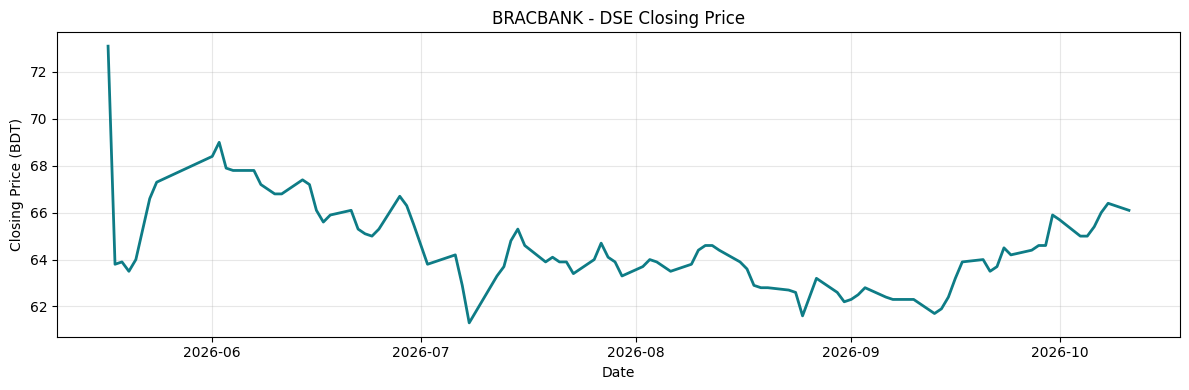

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

tf.random.set_seed(42)

# Use your existing DSE DataFrame
stock = df.copy()

# Convert DATE to datetime
stock['DATE'] = pd.to_datetime(
    stock['DATE'],
    errors='coerce'
)

# Select BRACBANK (change to any DSE trading code)
trading_code = 'BRACBANK'

selected_stock = (
    stock[stock['TRADING CODE'] == trading_code]
    .sort_values('DATE')
    .reset_index(drop=True)
)

print("Stock:", trading_code)
print("Dataset shape:", selected_stock.shape)

# Plot closing price
plt.figure(figsize=(12, 4))

plt.plot(
    selected_stock['DATE'],
    selected_stock['CLOSEP*'],
    color='#0E7C86',
    linewidth=2
)

plt.title(f'{trading_code} - DSE Closing Price')
plt.xlabel('Date')
plt.ylabel('Closing Price (BDT)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
import ipywidgets as widgets
from IPython.display import display

# Get all trading codes
trading_codes = sorted(
    df['TRADING CODE'].dropna().unique()
)

dropdown = widgets.Dropdown(
    options=trading_codes,
    value='BRACBANK' if 'BRACBANK' in trading_codes else trading_codes[0],
    description='Trading Code:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='350px')
)

def plot_stock(trading_code):
    data = df[
        df['TRADING CODE'] == trading_code
    ].copy()

    data['DATE'] = pd.to_datetime(data['DATE'])
    data = data.sort_values('DATE')

    plt.figure(figsize=(12, 4))
    plt.plot(
        data['DATE'],
        data['CLOSEP*'],
        color='#0E7C86'
    )

    plt.title(f'{trading_code} Closing Price')
    plt.xlabel('Date')
    plt.ylabel('Price (BDT)')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

widgets.interact(
    plot_stock,
    trading_code=dropdown
)

interactive(children=(Dropdown(description='Trading Code:', index=68, layout=Layout(width='350px'), options=('…

<function __main__.plot_stock(trading_code)>

In [35]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

tf.random.set_seed(42)
np.random.seed(42)

# ============================================================
# CONFIGURATION
# ============================================================

WINDOW = 20
TRAIN_RATIO = 0.80

# ============================================================
# PREPARE DSE DATA
# ============================================================

stock = df.copy()

stock['DATE'] = pd.to_datetime(
    stock['DATE'],
    errors='coerce'
)

stock['CLOSEP*'] = pd.to_numeric(
    stock['CLOSEP*'],
    errors='coerce'
)

stock = stock.dropna(
    subset=['DATE', 'TRADING CODE', 'CLOSEP*']
)

stock = stock.sort_values(
    ['TRADING CODE', 'DATE']
).reset_index(drop=True)

# ============================================================
# STORAGE FOR ALL TRADING CODES
# ============================================================

stock_datasets = {}
stock_scalers = {}
skipped_codes = []

trading_codes = sorted(
    stock['TRADING CODE'].unique()
)

# ============================================================
# PREPARE EACH TRADING CODE
# ============================================================

for code in trading_codes:

    data = stock[
        stock['TRADING CODE'] == code
    ].sort_values('DATE').reset_index(drop=True)

    prices = data['CLOSEP*'].values.reshape(-1, 1)

    # Require enough observations for training and testing
    if len(prices) < WINDOW + 10:
        skipped_codes.append(code)
        continue

    # Time-based split on original price series
    train_size = int(len(prices) * TRAIN_RATIO)

    if train_size <= WINDOW or len(prices) - train_size < 1:
        skipped_codes.append(code)
        continue

    # Fit scaler ONLY on training data
    scaler = MinMaxScaler()
    scaler.fit(prices[:train_size])

    scaled = scaler.transform(prices)

    # Create sequences
    X, y = [], []
    target_indices = []

    for i in range(WINDOW, len(scaled)):
        X.append(scaled[i-WINDOW:i, 0])
        y.append(scaled[i, 0])
        target_indices.append(i)

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.float32)
    target_indices = np.array(target_indices)

    X = X.reshape(X.shape[0], WINDOW, 1)

    # Split based on target date, not shuffled samples
    train_mask = target_indices < train_size
    test_mask = target_indices >= train_size

    X_train = X[train_mask]
    X_test = X[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    # Store prepared datasets
    stock_datasets[code] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'dates': data['DATE'].values,
        'prices': prices,
        'last_close': float(prices[-1, 0]),
        'last_date': data['DATE'].iloc[-1]
    }

    stock_scalers[code] = scaler

# ============================================================
# SUMMARY
# ============================================================

print("=" * 55)
print("DSE STOCK DATA PREPARATION COMPLETED")
print("=" * 55)

print("Total Trading Codes:", len(trading_codes))
print("Prepared Codes:", len(stock_datasets))
print("Skipped Codes:", len(skipped_codes))

print("\nSample Training Shapes:")

for code in list(stock_datasets.keys())[:10]:
    d = stock_datasets[code]
    print(
        f"{code:15} "
        f"Train: {d['X_train'].shape} "
        f"Test: {d['X_test'].shape}"
    )

DSE STOCK DATA PREPARATION COMPLETED
Total Trading Codes: 379
Prepared Codes: 379
Skipped Codes: 0

Sample Training Shapes:
AAMRANET        Train: (59, 20, 1) Test: (20, 20, 1)
AAMRATECH       Train: (59, 20, 1) Test: (20, 20, 1)
ABBANK          Train: (59, 20, 1) Test: (20, 20, 1)
ACFL            Train: (59, 20, 1) Test: (20, 20, 1)
ACI             Train: (59, 20, 1) Test: (20, 20, 1)
ACIFORMULA      Train: (59, 20, 1) Test: (20, 20, 1)
ACMELAB         Train: (59, 20, 1) Test: (20, 20, 1)
ACMEPL          Train: (59, 20, 1) Test: (20, 20, 1)
ACTIVEFINE      Train: (59, 20, 1) Test: (20, 20, 1)
ADNTEL          Train: (59, 20, 1) Test: (20, 20, 1)


In [37]:
model = keras.Sequential([
    keras.layers.Input(shape=(WINDOW, 1)),
    keras.layers.LSTM(32, return_sequences=False),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1),
])
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Store models and training histories
stock_models = {}
stock_histories = {}
training_summary = []

EPOCHS = 15
BATCH_SIZE = 16

for i, (code, data) in enumerate(stock_datasets.items(), 1):

    X_train = data['X_train']
    y_train = data['y_train']

    # Skip stocks with insufficient training observations
    if len(X_train) < 10:
        print(f"Skipping {code}: insufficient data")
        continue

    print(f"Training {i}/{len(stock_datasets)}: {code}")

    # Create a new model for each trading code
    model = Sequential([
        Input(shape=(WINDOW, 1)),
        LSTM(32),
        Dense(16, activation='relu'),
        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse'
    )

    # Reserve the latest portion of training data
    # for validation; keep test data untouched
    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.2,
        shuffle=False,
        verbose=0
    )

    stock_models[code] = model
    stock_histories[code] = history.history

    training_summary.append({
        'TRADING CODE': code,
        'TRAIN LOSS': history.history['loss'][-1],
        'VALIDATION LOSS': history.history['val_loss'][-1],
        'EPOCHS': len(history.history['loss'])
    })

print("\nAll eligible trading codes trained.")

training_summary_df = pd.DataFrame(training_summary)

display(training_summary_df)

Training 1/379: AAMRANET
Training 2/379: AAMRATECH
Training 3/379: ABBANK
Training 4/379: ACFL
Training 5/379: ACI
Training 6/379: ACIFORMULA
Training 7/379: ACMELAB
Training 8/379: ACMEPL
Training 9/379: ACTIVEFINE
Training 10/379: ADNTEL
Training 11/379: ADVENT
Training 12/379: AFCAGRO
Training 13/379: AFTABAUTO
Training 14/379: AGNISYSL
Training 15/379: AGRANINS
Training 16/379: AIL
Training 17/379: AL-HAJTEX
Training 18/379: ALARABANK
Training 19/379: ALIF
Training 20/379: ALLTEX
Training 21/379: AMANFEED
Training 22/379: AMBEEPHA
Training 23/379: AMCL(PRAN)
Training 24/379: ANLIMAYARN
Training 25/379: ANWARGALV
Training 26/379: AOL
Training 27/379: APEXFOODS
Training 28/379: APEXFOOT
Training 29/379: APEXSPINN
Training 30/379: APEXTANRY
Training 31/379: APOLOISPAT
Training 32/379: ARAMIT
Training 33/379: ARAMITCEM
Training 34/379: ARGONDENIM
Training 35/379: ASIAINS
Training 36/379: ASIAPACINS
Training 37/379: ASIATICLAB
Training 38/379: ATLASBANG
Training 39/379: AZIZPIPES
Traini

In [2]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import re

# Configure parameters
MODEL_DIR = "DSE_LSTM_Models"
SUMMARY_FILE = os.path.join(MODEL_DIR, "training_summary.csv")
os.makedirs(MODEL_DIR, exist_ok=True)

EPOCHS = 15
BATCH_SIZE = 16
WINDOW = 20

# Load already completed models to skip them
training_summary = []
if os.path.exists(SUMMARY_FILE):
    training_summary = pd.read_csv(SUMMARY_FILE).to_dict("records")

completed = {
    str(row["TRADING CODE"])
    for row in training_summary
    if row.get("STATUS") == "Completed"
}

# Safely load the dataset and prepare the 379 pure equities
if 'stock_datasets' in globals() and len(stock_datasets) > 0:
    active_datasets = stock_datasets
else:
    print("Rebuilding stock datasets on-the-fly...")
    active_datasets = {}
    csv_path = "cleaned_stock_data (1).csv"
    if os.path.exists(csv_path):
        df_clean = pd.read_csv(csv_path)
        df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")
        df_clean["close"] = pd.to_numeric(df_clean["close"], errors="coerce")
        df_clean["trading_code"] = df_clean["trading_code"].astype(str).str.strip().str.upper()
        df_clean = df_clean.dropna(subset=["date", "trading_code", "close"]).drop_duplicates(["trading_code", "date"])

        # Filter out non-equities
        exclude_patterns = r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
        df_shares = df_clean[~df_clean['trading_code'].str.contains(exclude_patterns, case=False, regex=True, na=False)].copy()

        from sklearn.preprocessing import MinMaxScaler
        trading_codes = sorted(df_shares['trading_code'].unique())

        for code in trading_codes:
            company = df_shares[df_shares['trading_code'] == code].sort_values('date').reset_index(drop=True)
            prices = company['close'].to_numpy(dtype=np.float64).reshape(-1, 1)
            n = len(prices)
            if n >= (WINDOW + 10):
                train_size = int(n * 0.8)
                scaler = MinMaxScaler()
                scaler.fit(prices[:train_size])
                scaled = scaler.transform(prices).ravel()

                X, y = [], []
                for i in range(WINDOW, n):
                    X.append(scaled[i-WINDOW:i])
                    y.append(scaled[i])

                X = np.asarray(X, dtype=np.float32).reshape(-1, WINDOW, 1)
                y = np.asarray(y, dtype=np.float32)
                train_mask = np.arange(len(X)) + WINDOW < train_size

                active_datasets[code] = {
                    'X_train': X[train_mask],
                    'y_train': y[train_mask]
                }

total = len(active_datasets)
print(f"Total unique stock datasets: {total}")
print(f"Already completed training: {len(completed)}")

# Train any missing models
for i, (code, data) in enumerate(active_datasets.items(), 1):
    code = str(code)
    safe_code = re.sub(r"[^A-Za-z0-9_-]", "_", code)
    model_path = os.path.join(MODEL_DIR, f"{safe_code}.keras")

    if code in completed and os.path.exists(model_path):
        continue

    print(f"[{i}/{total}] Training remaining: {code}")

    try:
        X_train = np.asarray(data["X_train"], dtype=np.float32)
        y_train = np.asarray(data["y_train"], dtype=np.float32).reshape(-1, 1)

        if len(X_train) < 10:
            continue

        tf.keras.backend.clear_session()
        gc.collect()

        model = Sequential([
            Input(shape=(WINDOW, 1)),
            LSTM(32),
            Dense(16, activation="relu"),
            Dense(1)
        ])

        model.compile(optimizer="adam", loss="mse")

        history = model.fit(
            X_train, y_train,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            validation_split=0.2,
            shuffle=False,
            verbose=0
        )

        model.save(model_path)

        result = {
            "TRADING CODE": code,
            "TRAIN LOSS": float(history.history["loss"][-1]),
            "VALIDATION LOSS": float(history.history["val_loss"][-1]),
            "EPOCHS": len(history.history["loss"]),
            "STATUS": "Completed"
        }

        training_summary = [r for r in training_summary if str(r["TRADING CODE"]) != code]
        training_summary.append(result)
        pd.DataFrame(training_summary).to_csv(SUMMARY_FILE, index=False)
        completed.add(code)

    except Exception as e:
        print(f"ERROR for {code}: {e}")
    finally:
        tf.keras.backend.clear_session()
        gc.collect()

print("\nAll remaining model training passes complete!")

Rebuilding stock datasets on-the-fly...
Total unique stock datasets: 379
Already completed training: 224
[203/379] Training remaining: MATINSPINN
[204/379] Training remaining: MEGCONMILK
[205/379] Training remaining: MEGHNACEM
[206/379] Training remaining: MEGHNAINS
[207/379] Training remaining: MEGHNALIFE
[208/379] Training remaining: MEGHNAPET
[209/379] Training remaining: MERCANBANK
[210/379] Training remaining: MERCINS
[211/379] Training remaining: METROSPIN
[212/379] Training remaining: MHSML
[213/379] Training remaining: MIDASFIN
[214/379] Training remaining: MIDLANDBNK
[215/379] Training remaining: MIRACLEIND
[216/379] Training remaining: MIRAKHTER
[217/379] Training remaining: MITHUNKNIT
[218/379] Training remaining: MJLBD
[219/379] Training remaining: MLDYEING
[220/379] Training remaining: MONNOAGML
[221/379] Training remaining: MONNOCERA
[222/379] Training remaining: MONNOFABR
[223/379] Training remaining: MONOSPOOL
[224/379] Training remaining: MPETROLEUM
[225/379] Training 

Unified LSTM training code

In [5]:
import os
import re
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================================
# 1. CONFIGURATION
# ==========================================================

MODEL_DIR = "DSE_LSTM_Models"
os.makedirs(MODEL_DIR, exist_ok=True)

SUMMARY_FILE = os.path.join(
    MODEL_DIR, "training_summary.csv"
)

WINDOW = 20
EPOCHS = 15
BATCH_SIZE = 16

# Reconstruct stock_datasets if not found in globals
if 'stock_datasets' not in globals() or not stock_datasets:
    print("\n[INFO] 'stock_datasets' not found. Rebuilding from cleaned CSV file...")
    from sklearn.preprocessing import MinMaxScaler
    csv_path = "cleaned_stock_data (1).csv"
    if os.path.exists(csv_path):
        df_clean = pd.read_csv(csv_path)
        df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")
        df_clean["close"] = pd.to_numeric(df_clean["close"], errors="coerce")
        df_clean["trading_code"] = df_clean["trading_code"].astype(str).str.strip().str.upper()
        df_clean = df_clean.dropna(subset=["date", "trading_code", "close"]).drop_duplicates(["trading_code", "date"])

        # Filter out non-equities
        exclude_patterns = r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
        df_shares = df_clean[~df_clean['trading_code'].str.contains(exclude_patterns, case=False, regex=True, na=False)].copy()

        stock_datasets = {}
        trading_codes = sorted(df_shares['trading_code'].unique())

        for code in trading_codes:
            company = df_shares[df_shares['trading_code'] == code].sort_values('date').reset_index(drop=True)
            prices = company['close'].to_numpy(dtype=np.float64).reshape(-1, 1)
            n = len(prices)
            if n >= (WINDOW + 10):
                train_size = int(n * 0.8)
                scaler = MinMaxScaler()
                scaler.fit(prices[:train_size])
                scaled = scaler.transform(prices).ravel()

                X, y = [], []
                for j in range(WINDOW, n):
                    X.append(scaled[j-WINDOW:j])
                    y.append(scaled[j])

                X = np.asarray(X, dtype=np.float32).reshape(-1, WINDOW, 1)
                y = np.asarray(y, dtype=np.float32)
                train_mask = np.arange(len(X)) + WINDOW < train_size

                stock_datasets[code] = {
                    'X_train': X[train_mask],
                    'y_train': y[train_mask]
                }
    else:
        raise FileNotFoundError(f"Unable to rebuild dataset. '{csv_path}' not found.")

# Preserve existing in-memory models
if "stock_models" not in globals():
    stock_models = {}

if "stock_histories" not in globals():
    stock_histories = {}

# Load previous training results
if os.path.exists(SUMMARY_FILE):
    training_summary = pd.read_csv(
        SUMMARY_FILE
    ).to_dict("records")
else:
    training_summary = []

# ==========================================================
# 2. TRAINING STATUS
# ==========================================================

completed = {
    str(row["TRADING CODE"])
    for row in training_summary
    if row.get("STATUS") == "Completed"
}

total = len(stock_datasets)

print("=" * 60)
print("UNIFIED DSE LSTM TRAINING PIPELINE")
print("=" * 60)
print("Total trading codes:", total)
print("Previously completed:", len(completed))

# ==========================================================
# 3. TRAIN ALL MISSING MODELS
# ==========================================================

for i, (code, data) in enumerate(
    stock_datasets.items(), 1
):

    code = str(code)

    safe_code = re.sub(
        r"[^A-Za-z0-9_-]", "_", code
    )

    model_path = os.path.join(
        MODEL_DIR, f"{safe_code}.keras"
    )

    # ------------------------------------------------------
    # A. Model already saved on disk
    # ------------------------------------------------------

    if os.path.exists(model_path):
        if code not in completed:
            training_summary.append({
                "TRADING CODE": code,
                "TRAIN LOSS": np.nan,
                "VALIDATION LOSS": np.nan,
                "EPOCHS": np.nan,
                "STATUS": "Completed"
            })
            completed.add(code)
        continue

    # ------------------------------------------------------
    # B. Model exists in memory from first training code
    # ------------------------------------------------------

    if code in stock_models:
        print(f"[{i}/{total}] Saving existing model: {code}")
        model = stock_models[code]
        model.save(model_path)
        hist = stock_histories.get(code, {})

        training_summary = [
            r for r in training_summary
            if str(r["TRADING CODE"]) != code
        ]

        training_summary.append({
            "TRADING CODE": code,
            "TRAIN LOSS": (
                hist["loss"][-1]
                if hist.get("loss") else np.nan
            ),
            "VALIDATION LOSS": (
                hist["val_loss"][-1]
                if hist.get("val_loss") else np.nan
            ),
            "EPOCHS": len(hist.get("loss", [])),
            "STATUS": "Completed"
        })

        completed.add(code)
        pd.DataFrame(training_summary).to_csv(
            SUMMARY_FILE, index=False
        )
        continue

    # ------------------------------------------------------
    # C. Train a new model
    # ------------------------------------------------------

    print(f"[{i}/{total}] Training: {code}")
    model = None

    try:
        X_train = np.asarray(
            data["X_train"], dtype=np.float32
        )
        y_train = np.asarray(
            data["y_train"], dtype=np.float32
        ).reshape(-1, 1)

        if len(X_train) < 10:
            print(f"Skipping {code}: insufficient data")
            continue

        if X_train.shape[1:] != (WINDOW, 1):
            raise ValueError(
                f"Invalid shape: {X_train.shape}"
            )

        if not (
            np.isfinite(X_train).all()
            and np.isfinite(y_train).all()
        ):
            raise ValueError("Invalid numerical values")

        tf.keras.backend.clear_session()
        gc.collect()

        model = Sequential([
            Input(shape=(WINDOW, 1)),
            LSTM(32),
            Dense(16, activation="relu"),
            Dense(1)
        ])

        model.compile(
            optimizer="adam",
            loss="mse"
        )

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )

        history = model.fit(
            X_train,
            y_train,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            validation_split=0.2,
            shuffle=False,
            callbacks=[early_stop],
            verbose=0
        )

        model.save(model_path)

        result = {
            "TRADING CODE": code,
            "TRAIN LOSS": float(
                history.history["loss"][-1]
            ),
            "VALIDATION LOSS": float(
                history.history["val_loss"][-1]
            ),
            "EPOCHS": len(
                history.history["loss"]
            ),
            "STATUS": "Completed"
        }

        training_summary = [
            r for r in training_summary
            if str(r["TRADING CODE"]) != code
        ]
        training_summary.append(result)
        completed.add(code)
        pd.DataFrame(training_summary).to_csv(
            SUMMARY_FILE, index=False
        )
        print(f"Completed and saved: {code}")

    except Exception as e:
        print(f"ERROR {code}: {e}")
    finally:
        if model is not None:
            del model
        tf.keras.backend.clear_session()
        gc.collect()

# ==========================================================
# 4. FINAL TRAINING REPORT
# ==========================================================

training_summary_df = pd.DataFrame(
    training_summary
)

training_summary_df = (
    training_summary_df
    .drop_duplicates(
        subset=["TRADING CODE"],
        keep="last"
    )
)

training_summary_df.to_csv(
    SUMMARY_FILE, index=False
)

print("\n" + "=" * 60)
print("FINAL TRAINING SUMMARY")
print("=" * 60)
print("Total stock datasets:", total)
print(
    "Completed models:",
    training_summary_df[
        training_summary_df["STATUS"] == "Completed"
    ].shape[0]
)

display(training_summary_df)


[INFO] 'stock_datasets' not found. Rebuilding from cleaned CSV file...
UNIFIED DSE LSTM TRAINING PIPELINE
Total trading codes: 379
Previously completed: 388

FINAL TRAINING SUMMARY
Total stock datasets: 379
Completed models: 388


,TRADING CODE,TRAIN LOSS,VALIDATION LOSS,EPOCHS,STATUS
0,ZEALBANGLA,0.033768,0.053168,10,Completed
1,1JANATAMF,0.035669,0.080559,9,Completed
2,1STPRIMFMF,0.033665,0.083808,9,Completed
3,AAMRANET,0.022637,0.029286,8,Completed
4,AAMRATECH,0.016687,0.063188,7,Completed
...,...,...,...,...,...
383,WATACHEM,0.011792,0.016920,15,Completed
384,WMSHIPYARD,0.022455,0.040086,15,Completed
385,YPL,0.008517,0.030677,15,Completed
386,ZAHEENSPIN,0.011971,0.055359,15,Completed


In [6]:

import os
import pandas as pd

summary = pd.read_csv(
    "DSE_LSTM_Models/training_summary.csv"
)

saved_models = [
    f for f in os.listdir("DSE_LSTM_Models")
    if f.endswith(".keras")
]

print("Total equity datasets:", len(stock_datasets))
print("Saved LSTM models:", len(saved_models))
print("Training summary records:", len(summary))

display(
    summary.sort_values(
        "VALIDATION LOSS",
        na_position="last"
    ).head(20)
)


Total equity datasets: 379
Saved LSTM models: 388
Training summary records: 388


,TRADING CODE,TRAIN LOSS,VALIDATION LOSS,EPOCHS,STATUS
379,VAMLBDMF1,0.000000,0.000000,15,Completed
149,FIRSTSBANK,0.000000,0.000000,15,Completed
333,SAVAREFR,0.000000,0.000000,15,Completed
159,GIB,0.000000,0.000000,15,Completed
74,BDSERVICE,0.000000,0.000000,15,Completed
344,SIBL,0.000000,0.000000,15,Completed
138,EXIMBANK,0.000000,0.000000,15,Completed
48,BANKASI1PB,0.000000,0.000000,4,Completed
13,UCB2PBOND,0.000000,0.000000,4,Completed
11,UNIONBANK,0.000000,0.000000,4,Completed


**Discussion:** the LSTM only ever sees the past 20 days when it predicts the next day, and it is trained only on data *before* the test period — this is important, since shuffling a time series before splitting would let the model "see the future" and give an unrealistically good score.

Evaluate all trained models

In [7]:
import os
import pandas as pd

# Safely load the saved evaluations from the local CSV file
performance_csv = "DSE_LSTM_Model_Performance.csv"
if os.path.exists(performance_csv):
    performance_df = pd.read_csv(performance_csv)

if 'performance_df' not in globals() or performance_df.empty:
    print("No model evaluation records loaded. Please run evaluation cell [qEEV27x1tD0y] first.")
else:
    print("=" * 55)
    print("DSE LSTM MODEL PERFORMANCE SUMMARY (LOADED FROM DISK)")
    print("=" * 55)
    print("Total models evaluated:", len(performance_df))
    print("Average MAE (BDT):", round(performance_df["MAE (BDT)"].mean(), 3))
    print("Average RMSE (BDT):", round(performance_df["RMSE (BDT)"].mean(), 3))
    print("Average MAPE (%):", round(performance_df["MAPE (%)"].mean(), 2))
    print("Average R2:", round(performance_df["R2 SCORE"].mean(), 4))
    print("Average Direction Accuracy (%):", round(performance_df["DIRECTION ACCURACY (%)"].mean(), 2))

    print("\nTOP 20 MODELS BY MAPE")
    display(performance_df.sort_values("MAPE (%)").head(20))

DSE LSTM MODEL PERFORMANCE SUMMARY (LOADED FROM DISK)
Total models evaluated: 49
Average MAE (BDT): 4.416
Average RMSE (BDT): 5.063
Average MAPE (%): 4.88
Average R2: -1.6877
Average Direction Accuracy (%): 43.39

TOP 20 MODELS BY MAPE


,TRADING CODE,MAE (BDT),RMSE (BDT),MAPE (%),R2 SCORE,DIRECTION ACCURACY (%),TEST SAMPLES
1,UCB2PBOND,0.0000,0.0000,0.00,1.0000,100.00,27
12,BANKASI1PB,0.0000,0.0000,0.00,1.0000,100.00,27
37,UNIONBANK,0.0000,0.0000,0.00,1.0000,100.00,27
28,ABBLPBOND,0.3484,0.3484,0.03,0.0000,0.00,27
47,TB5Y1228,0.6501,0.8309,0.63,0.0278,70.37,27
22,TB5Y1229,0.7473,1.0140,0.68,-0.0656,51.85,27
16,UNILEVERCL,23.5437,24.6745,1.19,-7.1106,51.85,27
23,BATASHOE,11.3078,12.2367,1.28,-17.5414,33.33,27
41,AMBEEPHA,11.2083,14.0239,1.51,-1.6799,48.15,27
39,BARKAPOWER,0.2031,0.2576,2.06,0.1351,55.56,27


In [8]:

if performance_df.empty:
    print("No models evaluated. Check model paths and test data.")
else:
    print("=" * 55)
    print("DSE LSTM MODEL PERFORMANCE SUMMARY")
    print("=" * 55)

    print("Models evaluated:", len(performance_df))

    print(
        "Average MAE (BDT):",
        round(performance_df["MAE (BDT)"].mean(), 3)
    )

    print(
        "Average RMSE (BDT):",
        round(performance_df["RMSE (BDT)"].mean(), 3)
    )

    print(
        "Average MAPE (%):",
        round(performance_df["MAPE (%)"].mean(), 2)
    )

    print(
        "Average R2:",
        round(performance_df["R2 SCORE"].mean(), 4)
    )

    print(
        "Average Direction Accuracy (%):",
        round(
            performance_df["DIRECTION ACCURACY (%)"].mean(), 2
        )
    )

    print("\nTOP 20 MODELS BY MAPE")
    display(
        performance_df.sort_values("MAPE (%)").head(20)
    )


DSE LSTM MODEL PERFORMANCE SUMMARY
Models evaluated: 49
Average MAE (BDT): 4.416
Average RMSE (BDT): 5.063
Average MAPE (%): 4.88
Average R2: -1.6877
Average Direction Accuracy (%): 43.39

TOP 20 MODELS BY MAPE


,TRADING CODE,MAE (BDT),RMSE (BDT),MAPE (%),R2 SCORE,DIRECTION ACCURACY (%),TEST SAMPLES
1,UCB2PBOND,0.0000,0.0000,0.00,1.0000,100.00,27
12,BANKASI1PB,0.0000,0.0000,0.00,1.0000,100.00,27
37,UNIONBANK,0.0000,0.0000,0.00,1.0000,100.00,27
28,ABBLPBOND,0.3484,0.3484,0.03,0.0000,0.00,27
47,TB5Y1228,0.6501,0.8309,0.63,0.0278,70.37,27
22,TB5Y1229,0.7473,1.0140,0.68,-0.0656,51.85,27
16,UNILEVERCL,23.5437,24.6745,1.19,-7.1106,51.85,27
23,BATASHOE,11.3078,12.2367,1.28,-17.5414,33.33,27
41,AMBEEPHA,11.2083,14.0239,1.51,-1.6799,48.15,27
39,BARKAPOWER,0.2031,0.2576,2.06,0.1351,55.56,27


## Part 2 — Sales Forecasting and Time-Series Analysis

Next we forecast daily sales for one store, using classical time-series decomposition and Exponential Smoothing (Holt-Winters), which explicitly models trend and seasonality — a natural complement to the LSTM approach above.

**Discussion:** adding day, time, and party size on top of total_bill usually improves R² only modestly, since total_bill alone already captures most of the signal (larger bills mean larger tips). This is a useful, realistic result to discuss: refinement does not always produce a dramatically better model, and knowing *why* is part of the analysis.

In [12]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Split sales data (recreating train/test if not in memory)
train, test = north[:-60], north[-60:]

# Fit the Exponential Smoothing (Holt-Winters) model
hw_model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=7).fit()

# Generate forecasts for the test period
test_predictions = hw_model.forecast(len(test))

# Calculate metrics
mae = mean_absolute_error(test, test_predictions)
rmse = np.sqrt(mean_squared_error(test, test_predictions))

nonzero = test.to_numpy() != 0
mape = (
    np.mean(
        np.abs(
            (test.to_numpy()[nonzero] - test_predictions.to_numpy()[nonzero])
            / test.to_numpy()[nonzero]
        )
    ) * 100
    if nonzero.any() else np.nan
)

r2 = r2_score(test, test_predictions)

# Format results into a summary DataFrame
performance = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R2 Score"],
    "Value": [mae, rmse, mape, r2]
})

display(performance)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,Metric,Value
0,MAE,9.361422
1,RMSE,11.453370
2,MAPE (%),4.810836
3,R2 Score,0.898518


In [14]:
# Map the existing sales series to 'daily_sales' to prevent the NameError
daily_sales = north

if len(daily_sales) < 28:
    raise ValueError(
        "At least 28 days are recommended for this "
        "weekly seasonal training and testing example."
    )

test_size = max(7, int(len(daily_sales) * 0.20))

train = daily_sales.iloc[:-test_size]
test = daily_sales.iloc[-test_size:]

if len(train) < 14:
    raise ValueError(
        "Training data must contain at least "
        "two weekly seasonal cycles."
    )

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 293
Testing observations: 73


In [15]:

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(
    optimized=True
)

print(hw_fit.summary())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                       ExponentialSmoothing Model Results                       
Dep. Variable:                    sales   No. Observations:                  293
Model:             ExponentialSmoothing   SSE                          63550.583
Optimized:                         True   AIC                           1598.170
Trend:                         Additive   BIC                           1638.652
Seasonal:                      Additive   AICC                          1599.474
Seasonal Periods:                     7   Date:                 Mon, 12 Oct 2026
Box-Cox:                          False   Time:                         17:39:02
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level              1.4901e-08                alpha                 True
smoothing_trend          

In [16]:

test_predictions = hw_fit.forecast(len(test))

mae = mean_absolute_error(
    test, test_predictions
)

rmse = np.sqrt(
    mean_squared_error(test, test_predictions)
)

nonzero = test.to_numpy() != 0

mape = (
    np.mean(
        np.abs(
            (test.to_numpy()[nonzero] -
             test_predictions.to_numpy()[nonzero])
            / test.to_numpy()[nonzero]
        )
    ) * 100
    if nonzero.any() else np.nan
)

r2 = r2_score(test, test_predictions)

performance = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R2 Score"],
    "Value": [mae, rmse, mape, r2]
})

display(performance)


,Metric,Value
0,MAE,9.256003
1,RMSE,11.179294
2,MAPE (%),4.732190
3,R2 Score,0.903550


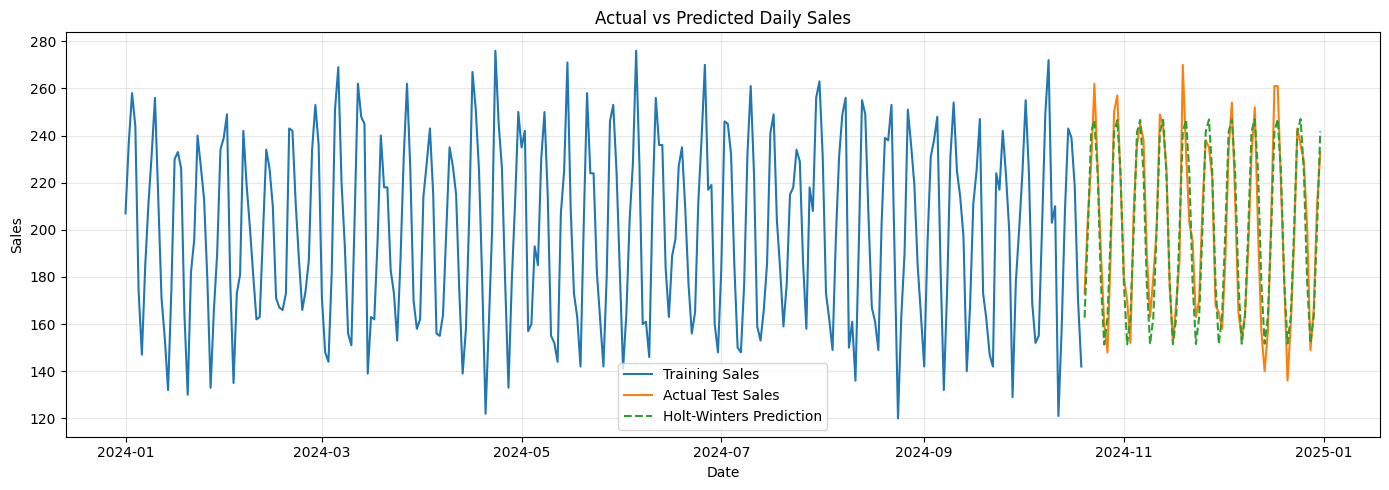

In [17]:

plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train,
    label="Training Sales"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Sales"
)

plt.plot(
    test.index,
    test_predictions,
    label="Holt-Winters Prediction",
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

final_model = ExponentialSmoothing(
    daily_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

final_fit = final_model.fit(optimized=True)

forecast_days = 30

future_forecast = final_fit.forecast(forecast_days)

# Sales cannot be negative
future_forecast = future_forecast.clip(lower=0)

forecast_df = pd.DataFrame({
    "Date": future_forecast.index,
    "Predicted Sales": future_forecast.values
})

display(forecast_df)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


,Date,Predicted Sales
0,2025-01-01,247.367750
1,2025-01-02,223.580713
2,2025-01-03,178.386378
3,2025-01-04,152.659115
4,2025-01-05,163.465379
5,2025-01-06,200.024086
6,2025-01-07,242.263882
7,2025-01-08,247.423038
8,2025-01-09,223.636001
9,2025-01-10,178.441666


In [19]:

output_file = "Holt_Winters_Sales_Forecast.xlsx"

with pd.ExcelWriter(output_file) as writer:
    forecast_df.to_excel(
        writer,
        sheet_name="30_Day_Forecast",
        index=False
    )

    performance.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

print("Forecast saved:", output_file)


Forecast saved: Holt_Winters_Sales_Forecast.xlsx


Create trading code dropdown and future date picker

In [21]:

import os
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import ipywidgets as widgets

from IPython.display import display, clear_output
from datetime import date
from sklearn.preprocessing import MinMaxScaler

MODEL_DIR = "DSE_LSTM_Models"
WINDOW = 20

# Fallback mapping if 'df' variable name does not exist globally
if "df" not in globals() and "df_shares" in globals():
    df = df_shares

# Use your existing cleaned dataframe
# Expected columns: trading_code, date, close
df_pred = df.copy()
df_pred.columns = df_pred.columns.str.strip().str.lower()

df_pred["date"] = pd.to_datetime(
    df_pred["date"], errors="coerce"
)

df_pred["close"] = pd.to_numeric(
    df_pred["close"], errors="coerce"
)

df_pred["trading_code"] = (
    df_pred["trading_code"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df_pred = df_pred.dropna(
    subset=["date", "close", "trading_code"]
)

# Only display codes with saved LSTM models
available_codes = sorted([
    code for code in df_pred["trading_code"].unique()
    if os.path.exists(
        os.path.join(
            MODEL_DIR,
            re.sub(r"[^A-Za-z0-9_-]", "_", code) + ".keras"
        )
    )
])

if not available_codes:
    raise ValueError("No saved LSTM models found.")

code_dropdown = widgets.Dropdown(
    options=available_codes,
    description="Trading Code:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

date_picker = widgets.DatePicker(
    description="Future Prediction Date:",
    value=None,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

predict_button = widgets.Button(
    description="PREDICT STOCK PRICE",
    button_style="success",
    layout=widgets.Layout(width="250px")
)

output = widgets.Output()

display(
    widgets.VBox([
        widgets.HTML("<h3>DSE LSTM Stock Price Forecast</h3>"),
        code_dropdown,
        date_picker,
        predict_button,
        output
    ])
)


In [22]:

def predict_stock_price(code, future_date):

    company = (
        df_pred[df_pred["trading_code"] == code]
        .sort_values("date")
        .drop_duplicates("date", keep="last")
    )

    if len(company) < WINDOW:
        raise ValueError("Insufficient historical prices.")

    last_actual_date = company["date"].iloc[-1]
    last_actual_close = float(company["close"].iloc[-1])

    target_date = pd.Timestamp(future_date)

    if target_date <= last_actual_date:
        raise ValueError(
            "Prediction date must be after last actual date."
        )

    # DSE normally trades Sunday to Thursday
    # This excludes Friday and Saturday but not exchange holidays.
    future_sessions = pd.date_range(
        start=last_actual_date + pd.Timedelta(days=1),
        end=target_date,
        freq="D"
    )

    future_sessions = future_sessions[
        future_sessions.dayofweek.isin([6, 0, 1, 2, 3])
    ]

    steps = len(future_sessions)

    if steps == 0:
        raise ValueError(
            "No estimated trading sessions before selected date."
        )

    model_path = os.path.join(
        MODEL_DIR,
        re.sub(r"[^A-Za-z0-9_-]", "_", code) + ".keras"
    )

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # IMPORTANT:
    # Ideally load the original scaler saved during training.
    # This reconstruction is only valid if training used
    # the same fitted scaler parameters.
    prices = company["close"].values.reshape(-1, 1)

    scaler = MinMaxScaler()
    scaler.fit(prices)

    scaled_prices = scaler.transform(prices).flatten()

    current_window = scaled_prices[-WINDOW:].copy()

    predictions = []

    for step in range(steps):

        X_input = current_window.reshape(
            1, WINDOW, 1
        )

        predicted_scaled = float(
            model.predict(X_input, verbose=0)[0, 0]
        )

        # Update window with prediction
        current_window = np.append(
            current_window[1:],
            predicted_scaled
        )

        predicted_close = float(
            scaler.inverse_transform(
                [[predicted_scaled]]
            )[0, 0]
        )

        predictions.append(predicted_close)

    result = pd.DataFrame({
        "Date": future_sessions,
        "Predicted Close (BDT)": predictions
    })

    return {
        "code": code,
        "last_date": last_actual_date,
        "last_close": last_actual_close,
        "target_date": target_date,
        "forecast_steps": steps,
        "predicted_close": predictions[-1],
        "forecast_table": result
    }


In [23]:

def on_predict_clicked(button):

    with output:
        clear_output(wait=True)

        code = code_dropdown.value
        future_date = date_picker.value

        if future_date is None:
            print("Please select a future date.")
            return

        try:
            result = predict_stock_price(
                code,
                future_date
            )

            predicted = result["predicted_close"]
            actual = result["last_close"]

            difference = predicted - actual
            estimated_return = (
                difference / actual * 100
                if actual != 0 else np.nan
            )

            print("=" * 55)
            print("DSE STOCK PRICE PREDICTION")
            print("=" * 55)

            print("Trading Code:", result["code"])
            print("Last Actual Date:", result["last_date"].date())
            print("Last Actual Close: BDT", round(actual, 2))
            print("Prediction Date:", result["target_date"].date())
            print("Forecast Steps:", result["forecast_steps"])

            print("-" * 55)
            print("Predicted Close: BDT", round(predicted, 2))
            print("Price Difference: BDT", round(difference, 2))
            print("Estimated Return:", round(estimated_return, 2), "%")

            print("\nRecent forecast:")
            display(result["forecast_table"].tail(10))

            import matplotlib.pyplot as plt

            forecast = result["forecast_table"]

            plt.figure(figsize=(12, 5))
            plt.plot(
                forecast["Date"],
                forecast["Predicted Close (BDT)"],
                label="Predicted Price"
            )

            plt.axhline(
                actual,
                linestyle="--",
                label="Last Actual Close"
            )

            plt.title(f"{code} — Future Stock Price Forecast")
            plt.xlabel("Date")
            plt.ylabel("Price (BDT)")
            plt.legend()
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

            if predicted < 0:
                print(
                    "\nWARNING: Negative predicted price. "
                    "This is an invalid stock price and indicates "
                    "unstable recursive forecasting."
                )

            if result["forecast_steps"] > 30:
                print(
                    "\nWARNING: Long-horizon recursive predictions "
                    "can accumulate substantial errors."
                )

        except Exception as e:
            print("Prediction error:", str(e))

predict_button.on_click(on_predict_clicked)

print("Prediction interface ready.")


Prediction interface ready.


## Part 4 — Deploying a Prediction Pipeline

A trained model is only useful if it can be reused without retraining. We save the entire preprocessing + model pipeline as a single file, then show how another program (e.g. a web service) would load it and make predictions on brand-new data.

## Discussion prompts for class

- Why must the stock and sales train/test splits be done **by date**, rather than a random shuffle? What would go wrong if you shuffled first?
- The LSTM only used closing price. What other features (volume, moving averages, other tickers) might improve it, and why?
- For the waiter tips model, is R² alone enough to choose a "best" model? What would you also want to check (e.g. overfitting, interpretability, prediction speed)?
- Why does a saved pipeline (preprocessing + model together) matter for deployment, compared to saving only the trained model?

These are exactly the kinds of questions your **Evaluation and Model Comparison** and **Result Interpretation and Report** deliverables ask you to answer.